<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn import preprocessing

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error as MSE

In [109]:
url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"
choc = pd.read_csv(url)
choc.head()

,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [110]:
#from google.colab import drive
#drive.mount('/content/drive')

<Axes: xlabel='company_location', ylabel='Avg Ratings'>

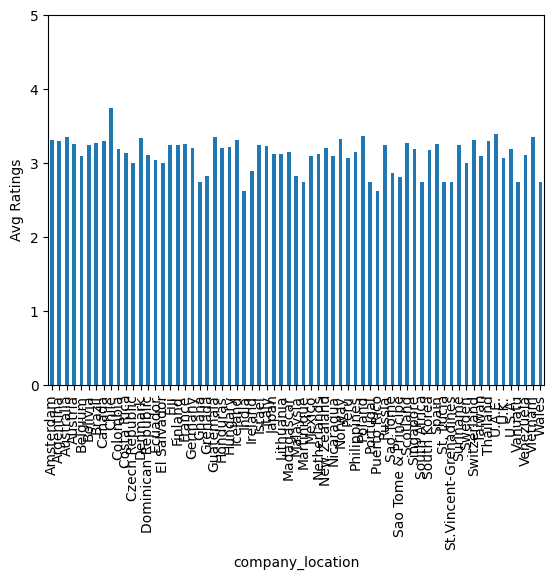

In [111]:
comp = choc.groupby("company_location")["rating"].mean()
ax = comp.plot(kind='bar')
ax.set_ylabel('Avg Ratings')
ax.set_ylim(0, 5)
ax

In [112]:
pd.get_dummies(choc["company_location"], prefix="location")

print(choc["company_location"].unique())
#Possible predictive question: Which factor of chocolate production determines the highest perception of chocolate quality?
#The origin of the bean?  Or the location of manufacturing/which manufacturer.  Which country or region leads to highest perception?

['U.S.A.' 'France' 'Fiji' 'Vanuatu' 'Ecuador' 'Mexico' 'U.K.'
 'Netherlands' 'Spain' 'Russia' 'Peru' 'Canada' 'Italy' 'Brazil'
 'Nicaragua' 'Australia' 'Philippines' 'Wales' 'Belgium' 'Vietnam'
 'Germany' 'Singapore' 'Switzerland' 'Venezuela' 'Malaysia' 'South Korea'
 'Taiwan' 'Puerto Rico' 'Colombia' 'Japan' 'New Zealand' 'Costa Rica'
 'Hungary' 'Amsterdam' 'Scotland' 'Martinique' 'Sao Tome' 'St. Lucia'
 'Argentina' 'Guatemala' 'South Africa' 'Dominican Republic'
 'Sao Tome & Principe' 'Bolivia' 'Portugal' 'Norway' 'Denmark' 'Grenada'
 'Israel' 'India' 'St.Vincent-Grenadines' 'Czech Republic' 'Thailand'
 'Finland' 'Madagascar' 'Sweden' 'Poland' 'Austria' 'Honduras' 'U.A.E.'
 'Lithuania' 'Ireland' 'Chile' 'Ghana' 'Iceland' 'Suriname' 'El Salvador']


In [113]:
pd.get_dummies(choc["country_of_bean_origin"], prefix="origin")

print(choc["country_of_bean_origin"].unique())

['Tanzania' 'Dominican Republic' 'Madagascar' 'Fiji' 'Venezuela' 'Uganda'
 'India' 'Bolivia' 'Peru' 'Panama' 'Colombia' 'Burma' 'Brazil'
 'Papua New Guinea' 'Ecuador' 'Cuba' 'Togo' 'Sao Tome' 'Mexico' 'Vanuatu'
 'Indonesia' 'Trinidad' 'Vietnam' 'Nicaragua' 'Ghana' 'Belize' 'Blend'
 'Jamaica' 'Grenada' 'Guatemala' 'Honduras' 'Costa Rica' 'Haiti' 'Congo'
 'Philippines' 'Solomon Islands' 'Malaysia' 'Sri Lanka' 'Ivory Coast'
 'Gabon' 'Taiwan' 'Puerto Rico' 'Martinique' 'St. Lucia' 'Australia'
 'Liberia' 'Sierra Leone' 'U.S.A.' 'Nigeria' 'St.Vincent-Grenadines'
 'Thailand' 'Tobago' 'Sao Tome & Principe' 'Sumatra' 'El Salvador'
 'Cameroon' 'Samoa' 'China' 'Principe' 'Sulawesi' 'Suriname' 'DR Congo']


In [114]:
# Convert cocoa percentage to numeric
choc["cocoa_numeric"] = (
    choc["cocoa_percent"]
    .str.replace("%", "", regex=False)
    .astype(float))

# Concatenate the dummy variables side-by-side to create a single features DataFrame
X = pd.concat([pd.get_dummies(choc["country_of_bean_origin"], prefix="origin"),
    pd.get_dummies(choc["company_location"], prefix="location"),
    pd.get_dummies(choc["ingredients"], prefix="ingredients"), choc[["cocoa_numeric"]]], axis=1)

y = choc["rating"].values

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=0)
print(X.shape)
display(X.head())

(2530, 151)


,origin_Australia,origin_Belize,origin_Blend,origin_Bolivia,origin_Brazil,origin_Burma,origin_Cameroon,origin_China,origin_Colombia,origin_Congo,...,"ingredients_4- B,S*,V,L","ingredients_4- B,S,C,L","ingredients_4- B,S,C,Sa","ingredients_4- B,S,C,V","ingredients_4- B,S,V,L","ingredients_5- B,S,C,L,Sa","ingredients_5- B,S,C,V,L","ingredients_5-B,S,C,V,Sa","ingredients_6-B,S,C,V,L,Sa",cocoa_numeric
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,76.0
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,76.0
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,76.0
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,68.0
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,72.0


In [115]:
# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model on the training data
model.fit(X_train, y_train)

# Evaluate the model on the training data
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print(f"Model successfully trained!")
print(f"Training R^2 Score: {train_r2:.4f}")
print(f"Model successfully tested!")
print(f"Test R^2 Score: {test_r2:.4f}")

Model successfully trained!
Training R^2 Score: 0.2012
Model successfully tested!
Test R^2 Score: -0.0549


In [116]:
#KNN
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
neighbors_list = [1,5,10,50,100]
scaler = preprocessing.StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

weights_list = ['uniform', 'distance']

for weight in weights_list:
    print(f"\nWeighting: {weight}")

    for k in neighbors_list:
        model2 = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight)

        model2.fit(X_train_s, y_train)

        y_train_fit = model2.predict(X_train_s)
        mse_train = np.mean((y_train - y_train_fit) ** 2)

        y_test_fit = model2.predict(X_test_s)
        mse_test = np.mean((y_test - y_test_fit) ** 2)

        cv_scores = cross_val_score(
            model2,
            X_train_s,
            y_train,
            cv=kfold,
            scoring='neg_mean_squared_error')

        mse_cv = -cv_scores.mean()

        print(
            f"k={k:3d} | "
            f"train RMSE={np.sqrt(mse_train):.3f} | "
            f"CV RMSE={np.sqrt(mse_cv):.3f} | "
            f"test RMSE={np.sqrt(mse_test):.3f}"
            )
# print(np.sqrt(mse_train), mse_train)


Weighting: uniform
k=  1 | train RMSE=0.295 | CV RMSE=0.572 | test RMSE=0.556
k=  5 | train RMSE=0.382 | CV RMSE=0.465 | test RMSE=0.450
k= 10 | train RMSE=0.411 | CV RMSE=0.457 | test RMSE=0.430
k= 50 | train RMSE=0.440 | CV RMSE=0.451 | test RMSE=0.417
k=100 | train RMSE=0.447 | CV RMSE=0.453 | test RMSE=0.417

Weighting: distance
k=  1 | train RMSE=0.295 | CV RMSE=0.572 | test RMSE=0.556
k=  5 | train RMSE=0.220 | CV RMSE=0.487 | test RMSE=0.470
k= 10 | train RMSE=0.215 | CV RMSE=0.480 | test RMSE=0.459
k= 50 | train RMSE=0.214 | CV RMSE=0.472 | test RMSE=0.451
k=100 | train RMSE=0.214 | CV RMSE=0.471 | test RMSE=0.450


In [117]:
# Assuming the column is named 'most_memorable_characteristics'
# We clean any extra whitespace and then split by comma using .str.get_dummies()
characteristics_dummies = choc['most_memorable_characteristics'].str.strip().str.get_dummies(sep=', ')

# Display the shape of the new dummy dataframe and some of the column names (characteristics)
print(f"Created {characteristics_dummies.shape[1]} unique characteristic dummy columns.")
print("\nFirst 10 characteristic columns:")
print(list(characteristics_dummies.columns[:10]))

# Show a preview of the new dummies DataFrame
display(characteristics_dummies.head())

Created 1034 unique characteristic dummy columns.

First 10 characteristic columns:
['"Andes" mint', 'Cadbury egg', 'Easter candy', 'Fruity', 'Rich cocoa', 'Roasty', 'XL nibs', 'accesible', 'accessible', 'acidic']


,"""Andes"" mint",Cadbury egg,Easter candy,Fruity,Rich cocoa,Roasty,XL nibs,accesible,accessible,acidic,...,wine,winey,wood,woodsy,woody,"woody,astringent","woody,green",wtf,yellow fruit,yogurt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [118]:
# 1. Clean characteristics_dummies by grouping its duplicate columns and summing them
if characteristics_dummies.columns.duplicated().any():
    print("Duplicate characteristic columns found. Aggregating them...")
    characteristics_cleaned = characteristics_dummies.T.groupby(level=0).sum().T
else:
    print("No duplicate characteristic columns found. They are already unique.")
    characteristics_cleaned = characteristics_dummies.copy()

# 2. Assign combined_features to be just the characteristics by itself
combined_features = characteristics_cleaned.astype(int)

print(f"Characteristics feature matrix shape: {combined_features.shape}")
display(combined_features.head())

No duplicate characteristic columns found. They are already unique.
Characteristics feature matrix shape: (2530, 1034)


,"""Andes"" mint",Cadbury egg,Easter candy,Fruity,Rich cocoa,Roasty,XL nibs,accesible,accessible,acidic,...,wine,winey,wood,woodsy,woody,"woody,astringent","woody,green",wtf,yellow fruit,yogurt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [119]:
# Split the combined features dataset into training and testing sets
X_train_comb, X_test_comb, y_train_comb, y_test_comb = train_test_split(
    combined_features, y, test_size=0.3, random_state=0)

# Initialize and train a new Linear Regression model
model_comb = LinearRegression()
model_comb.fit(X_train_comb, y_train_comb)

# Evaluate the model scores
train_r2_comb = model_comb.score(X_train_comb, y_train_comb)
test_r2_comb = model_comb.score(X_test_comb, y_test_comb)

print("--- Model Evaluation with Cleaned Characteristic Features ---")
print(f"Training R^2 Score: {train_r2_comb:.4f}")
print(f"Test R^2 Score: {test_r2_comb:.4f}")

--- Model Evaluation with Cleaned Characteristic Features ---
Training R^2 Score: 0.7732
Test R^2 Score: 0.3233


In [120]:
# Calculate the occurrence count of each binary feature
feature_counts = combined_features.sum().sort_values(ascending=False)

# Display the sorted frequency counts
print("Feature counts sorted in descending order (displaying the top 100 without truncation):")
with pd.option_context('display.max_rows', 100):
    display(feature_counts.head(100))

Feature counts sorted in descending order (displaying the top 100 without truncation):


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
creamy,186
sandy,164
fatty,163
floral,143
spicy,138


In [121]:
# Option A: Simply specify a number inside .head()
print("--- Top 30 Feature Counts ---")
display(feature_counts.head(30))

# Option B: Configure pandas to display more rows in general
# pd.set_option('display.max_rows', 100)
# display(feature_counts.head(100))

--- Top 30 Feature Counts ---


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
creamy,186
sandy,164
fatty,163
floral,143
spicy,138


In [122]:
# Get unique unique countries/locations
unique_locations = set(choc['company_location'].dropna().unique()).union(set(choc['country_of_bean_origin'].dropna().unique()))

# Get unique characteristics column names
unique_characteristics = set(characteristics_dummies.columns)

# Find exact intersections
exact_matches = unique_locations.intersection(unique_characteristics)

# Find partial matches (e.g., if a location name is a substring of a characteristic)
partial_matches = []
for char in unique_characteristics:
    for loc in unique_locations:
        # Ensure we don't match trivial short strings
        if len(loc) > 3 and loc.lower() in char.lower() and loc != char:
            partial_matches.append((char, loc))

print(f"Exact matches ({len(exact_matches)}):", exact_matches)
print(f"Partial matches ({len(partial_matches)}):", partial_matches)

Exact matches (0): set()
Partial matches (0): []


In [123]:
# Calculate the 90th percentile threshold
q_90 = feature_counts.quantile(0.9)
print(f"90th percentile threshold: {q_90}")

# Filter features that are at or below the 90th percentile
top_features = feature_counts[feature_counts >= q_90]
display(top_features)

90th percentile threshold: 13.0


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
...,...
savory,13
simple,13
flat,13
waxy,13


In [124]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

In [125]:
# Decision Tree Regression

# Hyperparameter values to test
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
leaf_list = [1, 2, 5, 10, 20, 30]

# Set up 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

best_rmse = float("inf")
best_depth = None
best_leaf = None

# Try different hyperparameter combinations
for depth in depth_list:
    for leaf in leaf_list:

        model_dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=0)

        cv_scores = cross_val_score(model_dt, X_train, y_train, cv=kfold, scoring="neg_mean_squared_error")

        cv_rmse = np.sqrt(-cv_scores.mean())

        print(
            f"max_depth={depth:2d} | "
            f"min_samples_leaf={leaf:2d} | "
            f"CV RMSE={cv_rmse:.3f}")

        if cv_rmse < best_rmse:
            best_rmse = cv_rmse
            best_depth = depth
            best_leaf = leaf

print("\nBest settings:")
print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_leaf)
print(f"Best CV RMSE: {best_rmse:.3f}")

max_depth= 2 | min_samples_leaf= 1 | CV RMSE=0.440
max_depth= 2 | min_samples_leaf= 2 | CV RMSE=0.440
max_depth= 2 | min_samples_leaf= 5 | CV RMSE=0.442
max_depth= 2 | min_samples_leaf=10 | CV RMSE=0.441
max_depth= 2 | min_samples_leaf=20 | CV RMSE=0.444
max_depth= 2 | min_samples_leaf=30 | CV RMSE=0.444
max_depth= 3 | min_samples_leaf= 1 | CV RMSE=0.440
max_depth= 3 | min_samples_leaf= 2 | CV RMSE=0.441
max_depth= 3 | min_samples_leaf= 5 | CV RMSE=0.439
max_depth= 3 | min_samples_leaf=10 | CV RMSE=0.439
max_depth= 3 | min_samples_leaf=20 | CV RMSE=0.441
max_depth= 3 | min_samples_leaf=30 | CV RMSE=0.441
max_depth= 4 | min_samples_leaf= 1 | CV RMSE=0.438
max_depth= 4 | min_samples_leaf= 2 | CV RMSE=0.440
max_depth= 4 | min_samples_leaf= 5 | CV RMSE=0.435
max_depth= 4 | min_samples_leaf=10 | CV RMSE=0.435
max_depth= 4 | min_samples_leaf=20 | CV RMSE=0.440
max_depth= 4 | min_samples_leaf=30 | CV RMSE=0.440
max_depth= 5 | min_samples_leaf= 1 | CV RMSE=0.440
max_depth= 5 | min_samples_leaf

In [126]:
# Evaluate the best Decision Tree model

# Build the best model using the manually selected hyperparameters
best_dt = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=0)

# Fit the model on the training data
best_dt.fit(X_train, y_train)

# Make predictions on training and testing data
y_train_pred_dt = best_dt.predict(X_train)
y_test_pred_dt = best_dt.predict(X_test)

# Calculate RMSE for training and testing sets
train_rmse_dt = np.sqrt(MSE(y_train, y_train_pred_dt))
test_rmse_dt = np.sqrt(MSE(y_test, y_test_pred_dt))

# Calculate MAE for the testing set
test_mae_dt = mean_absolute_error(y_test, y_test_pred_dt)

# Display model performance
print(f"Train RMSE: {train_rmse_dt:.3f}")
print(f"Test RMSE: {test_rmse_dt:.3f}")
print(f"Test MAE: {test_mae_dt:.3f}")

Train RMSE: 0.417
Test RMSE: 0.404
Test MAE: 0.330


In [127]:
# Baseline model using the mean rating

# Initialize and fit a Dummy Regressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

# Predict on the test set
y_test_pred_dummy = dummy.predict(X_test)

# Calculate baseline performance
dummy_rmse = np.sqrt(MSE(y_test, y_test_pred_dummy))
dummy_mae = mean_absolute_error(y_test, y_test_pred_dummy)

# Display baseline results
print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE: {dummy_mae:.3f}")

Baseline Test RMSE: 0.416
Baseline Test MAE: 0.342


In [128]:
# Evaluate the selected KNN model

# Use the best KNN settings found from tuning
best_knn = KNeighborsRegressor(
    n_neighbors=50,
    weights="uniform")

# Fit the model using standardized training data
best_knn.fit(X_train_s, y_train)

# Predict ratings on the standardized test data
y_test_pred_knn = best_knn.predict(X_test_s)

# Calculate KNN performance
knn_rmse = np.sqrt(MSE(y_test, y_test_pred_knn))
knn_mae = mean_absolute_error(y_test, y_test_pred_knn)

# Display KNN results
print(f"KNN Test RMSE: {knn_rmse:.3f}")
print(f"KNN Test MAE: {knn_mae:.3f}")

KNN Test RMSE: 0.417
KNN Test MAE: 0.341


In [129]:
# Diagnose Decision Tree prediction errors

# Create a table of actual and predicted ratings
error_df = pd.DataFrame({"Actual": y_test, "Predicted": y_test_pred_dt})

# Calculate prediction errors
error_df["Error"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute_Error"] = abs(error_df["Error"])

# Sort from largest to smallest prediction error
error_df = error_df.sort_values("Absolute_Error", ascending=False)

# Display the 20 largest prediction errors
display(error_df.head(20))

,Actual,Predicted,Error,Absolute_Error
422,1.50,3.294000,-1.794000,1.794000
449,2.00,3.319277,-1.319277,1.319277
101,2.00,3.232143,-1.232143,1.232143
581,2.00,3.056911,-1.056911,1.056911
638,2.00,3.056911,-1.056911,1.056911
466,2.00,3.056911,-1.056911,1.056911
345,2.00,3.056911,-1.056911,1.056911
411,2.25,3.294000,-1.044000,1.044000
480,3.25,2.212500,1.037500,1.037500
506,4.00,3.050000,0.950000,0.950000


In [130]:
# Examine the characteristics of the largest Decision Tree errors

# Keep the original row indices from the test set
test_indices = X_test.index

# Pull the original chocolate information for test observations
error_details = choc.loc[test_indices, ["company_location", "country_of_bean_origin", "cocoa_percent", "ingredients", "rating"]].copy()

# Add model predictions and absolute errors
error_details["Predicted"] = y_test_pred_dt
error_details["Absolute_Error"] = abs(error_details["rating"] - error_details["Predicted"])

# Sort from largest to smallest error
error_details = error_details.sort_values("Absolute_Error", ascending=False)

# Show the 20 largest errors
display(error_details.head(20))

,company_location,country_of_bean_origin,cocoa_percent,ingredients,rating,Predicted,Absolute_Error
2118,U.S.A.,Ghana,67%,"3- B,S,C",1.50,3.294000,1.794000
1446,Italy,Ecuador,70%,"4- B,S,C,L",2.00,3.319277,1.319277
1165,Ecuador,Ecuador,80%,"4- B,S,C,L",2.00,3.232143,1.232143
2295,U.S.A.,Peru,70%,"4- B,S,C,V",2.00,3.056911,1.056911
1283,Mexico,Mexico,72%,"5- B,S,C,V,L",2.00,3.056911,1.056911
1235,U.S.A.,Ghana,71%,"5- B,S,C,V,L",2.00,3.056911,1.056911
883,Switzerland,Blend,62%,"5- B,S,C,V,L",2.00,3.056911,1.056911
890,U.S.A.,Puerto Rico,65%,"3- B,S,C",2.25,3.294000,1.044000
2293,U.S.A.,Blend,99%,NaN,3.25,2.212500,1.037500
2459,U.K.,Colombia,70%,"3- B,S,C",4.00,3.050000,0.950000


In [131]:
# The best Decision Tree settings are max_depth = 6 and min_samples_leaf = 10.
# This combination had the lowest cross-validation RMSE about 0.433.
# Shallower trees performed slightly worse, while very deep trees with small leaves also had higher RMSE, suggesting that a moderate tree depth generalizes better.

In [132]:
# Identify the most important features in the Decision Tree

feature_importance = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False)

display(feature_importance.head(20))

,0
cocoa_numeric,0.584629
"ingredients_3- B,S,C",0.125823
"ingredients_2- B,S",0.099269
"ingredients_4- B,S,C,L",0.081306
location_U.S.A.,0.027934
location_France,0.025272
location_Italy,0.016589
location_U.K.,0.014660
origin_Venezuela,0.012776
origin_Dominican Republic,0.011741


In [134]:
# Cocoa percentage is the most important feature in the Decision Tree, accounting for about 58% of the model's total feature importance.
# Ingredient profiles also contribute to predictions, while individual geographic variables generally have much lower importance.

In [135]:
# Compare predictive model performance

model_comparison = pd.DataFrame({
    "Model": ["Dummy Baseline", "KNN", "Decision Tree"],
    "Test RMSE": [dummy_rmse, knn_rmse, test_rmse_dt],
    "Test MAE": [dummy_mae, knn_mae, test_mae_dt]})

display(model_comparison)

,Model,Test RMSE,Test MAE
0,Dummy Baseline,0.416081,0.341947
1,KNN,0.417461,0.341265
2,Decision Tree,0.403558,0.330076


In [136]:
# The Decision Tree performs best among the three models, with the lowest Test RMSE and Test MAE.
# However, the improvement over the baseline is relatively small, while KNN performs almost the same as the baseline.

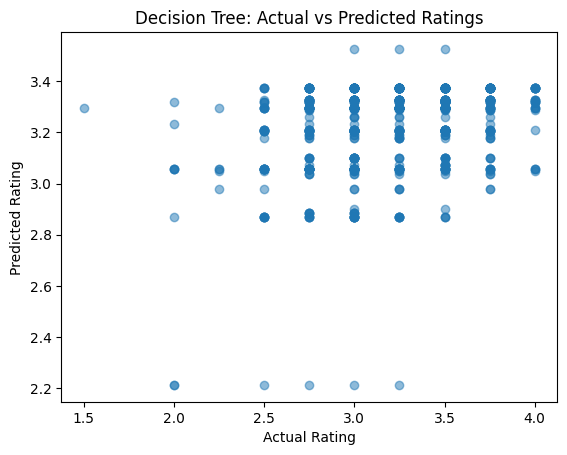

In [137]:
# Plot actual vs predicted ratings for the Decision Tree

plt.scatter(y_test, y_test_pred_dt, alpha=0.5)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Decision Tree: Actual vs Predicted Ratings")

plt.show()

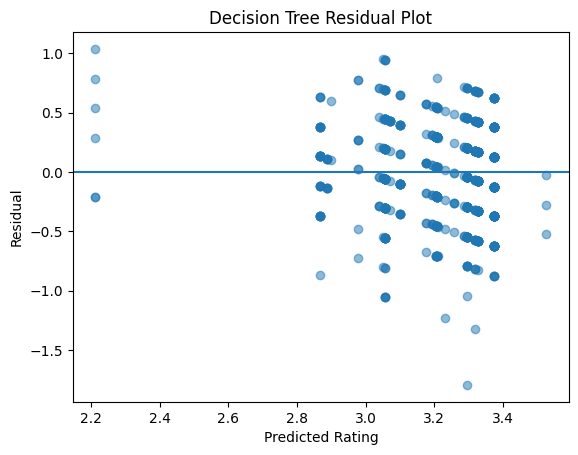

In [138]:
# Plot residuals for the Decision Tree

residuals = y_test - y_test_pred_dt

plt.scatter(y_test_pred_dt, residuals, alpha=0.5)
plt.axhline(0)

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")
plt.title("Decision Tree Residual Plot")

plt.show()

In [140]:
# Import PCA
from sklearn.decomposition import PCA

In [143]:
# Keep the more common sensory characteristics

q_90 = feature_counts.quantile(0.9)

common_features = feature_counts[feature_counts >= q_90].index

pca_features = characteristics_dummies[common_features]

print("Number of sensory features used:", pca_features.shape[1])
display(pca_features.head())

Number of sensory features used: 105


,sweet,nutty,cocoa,roasty,earthy,creamy,sandy,fatty,floral,spicy,...,ham,raspberry,deep cocoa,mint,few grits,savory,simple,flat,waxy,rustic
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [150]:
# Run PCA on the selected sensory characteristics

pca = PCA(n_components=2)

pca_result = pca.fit_transform(pca_features)

pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

print("PC1 explained variance:", pca.explained_variance_ratio_[0])
print("PC2 explained variance:", pca.explained_variance_ratio_[1])
print("Total explained variance:", pca.explained_variance_ratio_.sum())

display(pca_df.head())

PC1 explained variance: 0.05463290544349114
PC2 explained variance: 0.048246986012332266
Total explained variance: 0.10287989145582341


,PC1,PC2
0,-0.151414,-0.110104
1,0.109765,0.300525
2,0.106640,0.304634
3,-0.022043,-0.168764
4,-0.191202,-0.255340


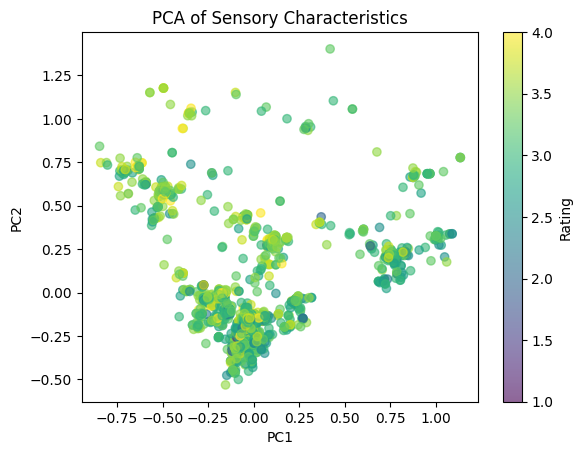

In [154]:
# Plot PC1 vs PC2 and color by rating

plt.scatter(pca_df["PC1"],pca_df["PC2"],c=choc["rating"],alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Sensory Characteristics")

plt.colorbar(label="Rating")
plt.show()

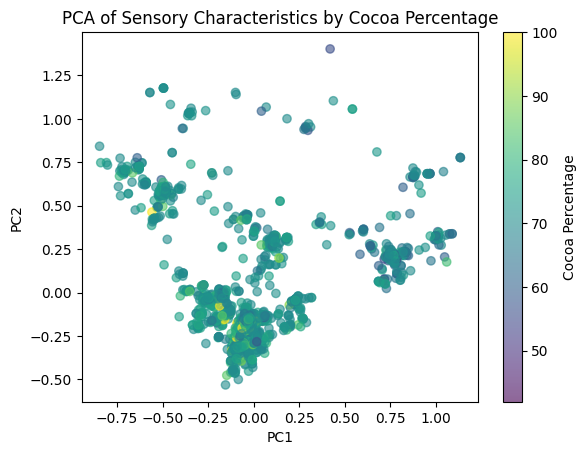

In [155]:
# Plot PC1 vs PC2 and color by cocoa percentage

plt.scatter(pca_df["PC1"], pca_df["PC2"], c=choc["cocoa_numeric"], alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Sensory Characteristics by Cocoa Percentage")

plt.colorbar(label="Cocoa Percentage")
plt.show()